# Lab01 - sprint 1

## Fifty Shades of Coffee

Исследуем влажность зёрен, дегустационную кислотность и полноту напитка. Цель — описать распределения, исследовать связи и получить оценки средних значений.

Влажность — физическая характеристика. `acidity` и `body` — округлённые сенсорные оценки; они не означают pH и плотность. [Описание исходного набора](https://github.com/jldbc/coffee-quality-database).

Данные доступны в `data/coffee_ratings.csv`. Все решения по подготовке данных приведены ниже. Таблицу вклада команды в конце заполняют участники.


## Подготовка данных

Одна строка описывает оценённый образец/партию. Воображаемый случайный эксперимент: выбрать одну подходящую запись об арабике и посмотреть значение показателя. Равновероятный выбор строки задаёт эмпирическое распределение. Распределение всей арабики в мире по этому набору неизвестно: сертификационный отбор не является случайным отбором мировой продукции.


### Критерий 1: обоснование стохастической природы

Требование трактуем как необходимость обосновать вероятностную модель наблюдений: до проведения измерения или дегустации точное значение нельзя однозначно получить из известных характеристик образца. Нужно назвать источники вариации, а не только предложить случайно выбрать строку таблицы.

**Граница утверждения.** По конечной таблице невозможно доказать отсутствие любой детерминированной формулы. Неизвестность формулы, разброс значений и ненормальность распределения по отдельности не доказывают стохастическую природу. Приведённые ниже аргументы обосновывают применение вероятностной модели, а не фундаментальную недетерминированность физического мира.

Модель для сенсорного балла можно записать как

\[
R_{ij}=\mu_i+a_j+\varepsilon_{ij},
\]

где \(\mu_i\) — средний балл образца \(i\) в заданных условиях, \(a_j\) — эффект дегустатора \(j\), а \(\varepsilon_{ij}\) — вариация конкретной процедуры оценивания. При фиксированном дегустаторе его эффект не обязательно случаен; при выборе дегустатора из группы его можно моделировать случайным. Ни нормальность, ни независимость этих компонентов здесь не предполагаются автоматически.

Это модель, мотивированная способом получения результатов. В данном CSV нет явно размеченных серий повторных оценок каждого образца разными экспертами, поэтому раздельно оценить эти компоненты по нашей работе нельзя. Источники о сенсорном анализе объясняют природу подобных оценок, но не заменяют отсутствующие повторные измерения именно этого набора.

Наличие измерительной формулы также совместимо со случайными входными величинами и неопределённостью результата: этот подход рассматривается в [JCGM GUM-6:2020, приложение C](https://www.bipm.org/documents/20126/2071204/JCGM_GUM_6_2020.pdf).


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 12)

candidates = [Path("data/coffee_ratings.csv"), Path("../data/coffee_ratings.csv")]
local_path = next((path for path in candidates if path.exists()), None)
data_path = local_path if local_path is not None else "https://raw.githubusercontent.com/Mironiks007/fifty-shades-of-coffee/main/data/coffee_ratings.csv"
raw = pd.read_csv(data_path)
columns = ["moisture", "acidity", "body"]
print("Размер исходной таблицы:", raw.shape)
print("Полные дубликаты:", raw.duplicated().sum())
print("Виды кофе:")
print(raw["species"].value_counts().to_string())
print("Пропуски выбранных показателей:")
print(raw[columns].isna().sum().to_string())
print("Нули выбранных показателей:")
print(raw[columns].eq(0).sum().to_string())


Размер исходной таблицы: (1339, 43)
Полные дубликаты: 0
Виды кофе:
species
Arabica    1311
Robusta      28
Пропуски выбранных показателей:
moisture    0
acidity     0
body        0
Нули выбранных показателей:
moisture    264
acidity       1
body          1


В основной анализ включаем только Arabica, чтобы получить более однородный объект исследования. Строки с нулевой влажностью считаем подозрительными: документация предоставленного файла не объясняет такие нули. Не называем их подтверждённым кодом пропуска. Строку с нулевыми сенсорными оценками также исключаем. Применяем единое правило: выбранные значения заполнены и положительны. Такое исключение может вносить смещение, поэтому ниже сравниваем сенсорные результаты с выборкой, где нули влажности оставлены. Все ненулевые выбросы сохраняем.


In [2]:
arabica = raw.loc[raw["species"].eq("Arabica")].copy()
complete = arabica.dropna(subset=columns)
valid = complete[columns].gt(0).all(axis=1)
data = complete.loc[valid].copy()
print("Исходных записей Arabica:", len(arabica))
print("Исключено из-за пропусков:", len(arabica) - len(complete))
print("Исключено из-за неположительных значений:", (~valid).sum())
print("Основная выборка:", len(data))
assert len(data) >= 1000
assert data[columns].notna().all().all()
assert data[columns].gt(0).all().all()
print(data[columns].describe().round(4).to_string())


Исходных записей Arabica: 1311
Исключено из-за пропусков: 0
Исключено из-за неположительных значений: 253
Основная выборка: 1058
        moisture    acidity       body
count  1058.0000  1058.0000  1058.0000
mean      0.1100     7.5266     7.5030
std       0.0228     0.3141     0.2856
min       0.0100     6.0800     6.3300
25%       0.1000     7.3300     7.3300
50%       0.1100     7.5000     7.5000
75%       0.1200     7.7500     7.6700
max       0.2800     8.7500     8.5800


## Общие методы

Для описания используем среднее $\bar x=\frac1n\sum x_i$, медиану, исправленную дисперсию $s^2=\frac1{n-1}\sum(x_i-\bar x)^2$, стандартное отклонение и квартили.

Графики показывают гистограмму, эмпирическую функцию распределения, boxplot и нормальный Q–Q график. Правило $1.5\,IQR$ только отмечает необычные значения; оно не служит основанием для удаления.

Проверка Д’Агостино–Пирсона сравнивает данные с нормальным распределением. Оценки округлены, а влажность ограничена физически, поэтому нормальное распределение рассматриваем как приближение. Отсутствие отклонения гипотезы не доказывает нормальность. Уровень значимости 0.05; для трёх проверок используем поправку Холма.

Доверительный интервал среднего: $\bar x\pm t_{0.975,n-1}s/\sqrt n$. Дополнительно строим процентильный bootstrap-интервал. Оба подхода здесь используют предположение независимости строк.


In [3]:
def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty(len(p_values))
    ranked = p_values[order] * (len(p_values) - np.arange(len(p_values)))
    adjusted[order] = np.minimum(1, np.maximum.accumulate(ranked))
    return adjusted

normality_rows = []
interval_rows = []
for column in columns:
    values = data[column].to_numpy()
    normality = stats.normaltest(values)
    normality_rows.append({"variable": column, "statistic": normality.statistic, "p_value": normality.pvalue})
    n = len(values)
    mean = values.mean()
    standard_error = values.std(ddof=1) / np.sqrt(n)
    t_low, t_high = stats.t.interval(0.95, df=n-1, loc=mean, scale=standard_error)
    bootstrap_rng = np.random.default_rng(SEED)
    bootstrap_means = bootstrap_rng.choice(values, size=(2000, n), replace=True).mean(axis=1)
    b_low, b_high = np.quantile(bootstrap_means, [0.025, 0.975])
    interval_rows.append({"variable": column, "n": n, "mean": mean, "t_low": t_low, "t_high": t_high, "bootstrap_low": b_low, "bootstrap_high": b_high})
normality_table = pd.DataFrame(normality_rows).set_index("variable")
normality_table["p_holm"] = holm_adjust(normality_table["p_value"])
interval_table = pd.DataFrame(interval_rows).set_index("variable")
print("Проверка нормальности:")
print(normality_table.to_string(float_format=lambda value: f"{value:.5g}"))
print("Средние и 95% доверительные интервалы:")
print(interval_table.round(5).to_string())


Проверка нормальности:
          statistic    p_value     p_holm
variable                                 
moisture     350.17 9.1492e-77 2.7448e-76
acidity      29.572 3.7886e-07 7.5773e-07
body          28.17 7.6388e-07 7.6388e-07
Средние и 95% доверительные интервалы:
             n     mean    t_low   t_high  bootstrap_low  bootstrap_high
variable                                                                
moisture  1058  0.11000  0.10862  0.11138        0.10864         0.11133
acidity   1058  7.52662  7.50767  7.54557        7.50814         7.54521
body      1058  7.50303  7.48580  7.52027        7.48606         7.52013


## Критерий 6: математическая база распределений и их особенности

### Какое распределение описываем

Точный закон измерений в реальной совокупности кофе неизвестен. Для каждой из трёх величин используем **конечное эмпирическое распределение**, полностью определённое подготовленной таблицей. Оно не требует подгонять нормальный, гамма- или иной параметрический закон. Гистограмма сама по себе не устанавливает семейство распределений.

Пусть $N=1058$, $I$ равновероятно выбирает номер строки: $P(I=i)=1/N$, а $X=x_I$ — значение одного показателя в этой строке. Уникальные значения обозначим $a_1<\dots<a_K$, их количества — $c_1,\dots,c_K$. Тогда **функция вероятностей (PMF)** имеет вид
\[
p_j=P_{emp}(X=a_j)=\frac{c_j}{N},\qquad p_j>0,\qquad\sum_{j=1}^Kp_j=1.
\]
Вероятности уникальных значений обычно **не равны** друг другу: равновероятны строки, а не разные баллы. При отсутствии значения в таблице его эмпирическая вероятность равна нулю; это не означает невозможности такого значения в реальном мире.

Эмпирическая **функция распределения (CDF)**:
\[
F_N(t)=P_{emp}(X\le t)=\sum_{a_j\le t}p_j
      =\frac1N\sum_{i=1}^N\mathbf1\{x_i\le t\}.
\]
Она не убывает, непрерывна справа и имеет скачок величины $p_j$ в точке $a_j$. Ниже минимума $F_N(t)=0$, начиная с максимума $F_N(t)=1$. Например,
\[
P_{emp}(a<X\le b)=F_N(b)-F_N(a).
\]
Такая модель дискретна из-за конечной рамки выбора строк. Округление записей дополнительно создаёт совпадающие значения. Это не означает, что физическая влажность сама по себе принимает только значения из CSV.

### Параметры и форма

Из функции вероятностей получаем математическое ожидание, дисперсию и центральные моменты:
\[
\mu_{emp}=\sum_j a_jp_j=\bar x,\qquad
\sigma_{emp}^2=\sum_j(a_j-\mu_{emp})^2p_j
              =\frac1N\sum_i(x_i-\bar x)^2,
\]
\[
\gamma_1=\frac{E_{emp}[(X-\mu_{emp})^3]}{\sigma_{emp}^3},\qquad
\gamma_2=\frac{E_{emp}[(X-\mu_{emp})^4]}{\sigma_{emp}^4}-3.
\]
Здесь дисперсия с делителем **N** — точный параметр эмпирического закона. Исправленная дисперсия с делителем **N−1** выше использовалась как выборочная оценка и имеет другую роль. Коэффициенты $\gamma_1,\gamma_2$ ниже также вычислены как точные моменты эмпирического закона, поэтому немного отличаются от оценок с поправкой на смещение в EDA.

Мода — любое значение с наибольшим $p_j$; мод может быть несколько. Квантиль уровня $q\in(0,1)$ определяется как $Q(q)=\inf\{t:F_N(t)\ge q\}$. В EDA квартиль считается стандартной линейной интерполяцией pandas/NumPy; это другая допустимая выборочная конвенция, поэтому не утверждаем её тождественность этому определению квантиля.

Отрицательная асимметрия характеризует преобладание отрицательных кубических отклонений; положительная — положительных. Эксцесс сравнивает четвёртый стандартизованный момент с нормальным законом, а не определяет форму по одному числу. Нулевая асимметрия и нулевой эксцесс по отдельности или вместе не доказывают нормальность.

### Нормальный закон как модель для сравнения

Для $Y\sim\mathcal N(\mu,\sigma^2)$, $\sigma>0$,
\[
f_Y(y)=\frac1{\sigma\sqrt{2\pi}}
\exp\!\left[-\frac{(y-\mu)^2}{2\sigma^2}\right],\qquad y\in\mathbb R,
\]
\[
F_Y(y)=\Phi\!\left(\frac{y-\mu}{\sigma}\right),\qquad
\Phi(z)=\int_{-\infty}^{z}\frac{e^{-u^2/2}}{\sqrt{2\pi}}\,du.
\]
У нормального закона $E(Y)=\mu$, $Var(Y)=\sigma^2$; он симметричен, одномодален, среднее/медиана/мода совпадают, асимметрия и эксцесс равны нулю. Поддержка — вся числовая прямая. $f_Y(y)$ — **плотность**, а не вероятность точки: $P(Y=y)=0$, вероятность интервала равна интегралу плотности. У дискретной модели выше вероятность наблюдаемого значения положительна. Поэтому высоты PMF и непрерывной плотности не сравниваем как одинаковые величины.

В гистограммах EDA нормальная кривая построена с $\mu=\bar x$, $\sigma=s$ (`ddof=1`) как наглядный ориентир, не как установленный истинный закон. Это не утверждение об оценках максимального правдоподобия. На Q–Q-графике нормальная модель ожидает приблизительно прямую линию; систематические отклонения показывают её ограничения.

Для всех трёх столбцов ранее получено отклонение нормальности тестом Д’Агостино–Пирсона с поправкой Холма. Округление и повторы означают, что обычная калибровка теста для iid непрерывных наблюдений не является точной моделью этих записей; p-значения рассматриваем вместе с графиками как диагностику непрерывного приближения. Точный дискретный эмпирический закон в любом случае не тождествен непрерывному нормальному закону. Альтернативное параметрическое семейство автоматически не назначаем.

Стандартизация $Z=(X-\mu)/\sigma$ даёт среднее 0 и дисперсию 1, но делает $Z$ стандартно нормальной **только если X уже нормальна**. Центральная предельная теорема при соответствующих условиях относится к распределению среднего по повторным выборкам, а не превращает исходные баллы в нормальные.

Источники: [Penn State: PMF и CDF дискретной величины](https://online.stat.psu.edu/stat414/Lesson07), [NIST: нормальное распределение](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3661.htm).



moisture: пять наиболее частых значений
 value  count  probability      CDF
  0.11    381     0.360113 0.617202
  0.12    283     0.267486 0.884688
  0.10    180     0.170132 0.257089
  0.13     75     0.070888 0.955577
  0.09     26     0.024575 0.086957

acidity: пять наиболее частых значений
 value  count  probability      CDF
  7.50    134     0.126654 0.531191
  7.58    118     0.111531 0.642722
  7.67    110     0.103970 0.747637
  7.42    108     0.102079 0.404537
  7.33     94     0.088847 0.302457

body: пять наиболее частых значений
 value  count  probability      CDF
  7.50    162     0.153119 0.573724
  7.67    124     0.117202 0.794896
  7.33    116     0.109641 0.316635
  7.42    110     0.103970 0.420605
  7.58    109     0.103025 0.676749

Математические характеристики эмпирических распределений:
             N  unique_values  support_min  support_max modes  mode_probability  mean_emp  variance_emp_ddof0  skewness_emp  excess_emp
variable                               

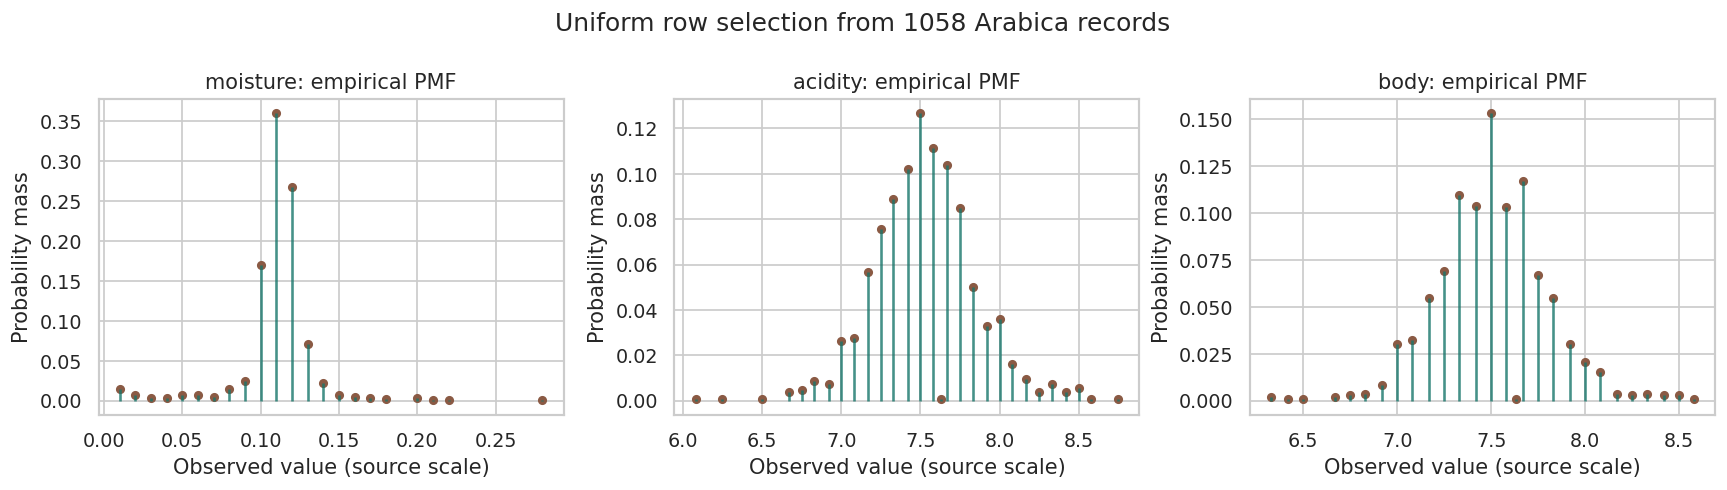

In [4]:
distribution_tables = {}
distribution_math_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, column in zip(axes, columns):
    counts = data[column].value_counts().sort_index()
    support = counts.index.to_numpy(dtype=float)
    probabilities = counts.to_numpy() / len(data)
    distribution_table = pd.DataFrame({
        "value": support, "count": counts.to_numpy(),
        "probability": probabilities, "CDF": probabilities.cumsum(),
    })
    distribution_tables[column] = distribution_table
    mean = np.sum(support * probabilities)
    variance = np.sum((support - mean)**2 * probabilities)
    skewness = np.sum((support - mean)**3 * probabilities) / variance**1.5
    excess = np.sum((support - mean)**4 * probabilities) / variance**2 - 3
    modes = support[counts.to_numpy() == counts.max()]
    distribution_math_rows.append({
        "variable": column, "N": len(data), "unique_values": len(support),
        "support_min": support.min(), "support_max": support.max(),
        "modes": ", ".join(f"{value:g}" for value in modes),
        "mode_probability": probabilities.max(),
        "mean_emp": mean, "variance_emp_ddof0": variance,
        "skewness_emp": skewness, "excess_emp": excess,
    })
    assert counts.sum() == len(data)
    assert np.isclose(probabilities.sum(), 1)
    assert np.all(np.diff(distribution_table["CDF"]) >= 0)
    assert np.isclose(distribution_table["CDF"].iloc[-1], 1)
    assert np.isclose(mean, data[column].mean())
    assert np.isclose(variance, data[column].var(ddof=0))
    axis.vlines(support, 0, probabilities, color="#18766b", alpha=.8)
    axis.scatter(support, probabilities, color="#8a5a44", s=18)
    axis.set(title=f"{column}: empirical PMF", xlabel="Observed value (source scale)", ylabel="Probability mass")
    print(f"\n{column}: пять наиболее частых значений")
    print(distribution_table.sort_values(["count", "value"], ascending=[False, True]).head(5).round(6).to_string(index=False))
fig.suptitle(f"Uniform row selection from {len(data)} Arabica records")
fig.tight_layout()
plt.show()
distribution_math_table = pd.DataFrame(distribution_math_rows).set_index("variable")
print("\nМатематические характеристики эмпирических распределений:")
print(distribution_math_table.round(6).to_string())


### Особенности распределения каждой величины

| Показатель | Различных значений | Наблюдаемый диапазон | Мода и её вероятность | Асимметрия | Эксцесс |
| --- | --- | --- | --- | --- | --- |
| moisture | 22 | [0.01; 0.28] | 0.11 (36.0%) | -1.108 | 10.501 |
| acidity | 29 | [6.08; 8.75] | 7.5 (12.7%) | 0.115 | 1.166 |
| body | 28 | [6.33; 8.58] | 7.5 (15.3%) | 0.060 | 1.177 |

У влажности выражена отрицательная асимметрия, а крайние наблюдения заметно влияют на четвёртый момент. Кислотность и полнота напитка имеют небольшую положительную асимметрию; близость к симметрии не делает их нормальными. Положительный эксцесс указывает на больший четвёртый стандартизованный момент, чем у нормального закона; по одному этому числу не устанавливаем точный тип хвостов.

Перечисленные диапазоны — крайние значения в подготовленной таблице, а не доказанные физические границы влажности или полная допустимая шкала баллов. Сенсорные оценки округлены, поэтому видны скопления вероятностей на повторяющихся значениях. Все моменты эмпирических законов конечны из-за конечной поддержки.

**Для конечной рамки отбора распределения заданы полностью таблицами `distribution_tables`: значениями, частотами, вероятностями и CDF.** Для неизвестной реальной совокупности это непараметрическое описание доступных данных, а не доказанный закон всего кофе. Нормальное распределение описано математически и используется для сравнения с указанными ограничениями.


## Random Variable 01 — Влажность зёрен

### Description

Влажность описывает содержание воды в зёрнах. Анализируем исходную числовую шкалу CSV, не заменяя её баллами или концентрацией кофеина. Точность и метод измерения каждой записи в этом файле не раскрыты.

Случайная величина: значение `moisture` для выбранной записи Arabica после явно заданного отбора. Наблюдаемые значения округлены; их эмпирическое распределение дискретно.


#### Стохастическая природа влажности

Влажность является результатом измерения физического свойства. На содержание воды влияют история сушки и хранения, влажность среды и неоднородность отобранной пробы. В руководстве University of Hawai‘i описана зависимость влажности зёрен от среды, а также вариабельность показаний при повторном предъявлении образца влагомеру. Это содержательные основания учитывать межобразцовую и измерительную вариацию [1].

Например, при гравиметрическом методе результат рассчитывают по измеренным массам:

\[
w=\frac{m_{\mathrm{до}}-m_{\mathrm{после}}}{m_{\mathrm{до}}}.
\]

Это **формула обработки измерений**, а не способ заранее определить влажность конкретного образца по его стране, сорту или названию фермы. Значения масс сначала нужно получить экспериментально. Конкретный метод, использованный для каждой записи CQI, в нашем CSV не установлен; формула приведена как пример, а не как утверждение о методе всего набора.

**Вывод:** моделирование наблюдаемой влажности как случайной величины обосновано вариацией содержания воды между пробами и возможной вариацией измерительного процесса. Вклад приборной вариации в нашем наборе отдельно не измерен. Буквальное утверждение «для влажности не существует формулы» неверно.

[1] Gautz L. D., Smith V. E., Bittenbender H. C. *Measuring Coffee Bean Moisture Content*. University of Hawai‘i, 2008. https://www.ctahr.hawaii.edu/oc/freepubs/pdf/EN-3.pdf


### EDA & Distribution


n                 1058.00000
mean                 0.11000
median               0.11000
variance_ddof1       0.00052
std_ddof1            0.02279
min                  0.01000
q1                   0.10000
q3                   0.12000
max                  0.28000
skewness            -1.10924
IQR_flags           74.00000


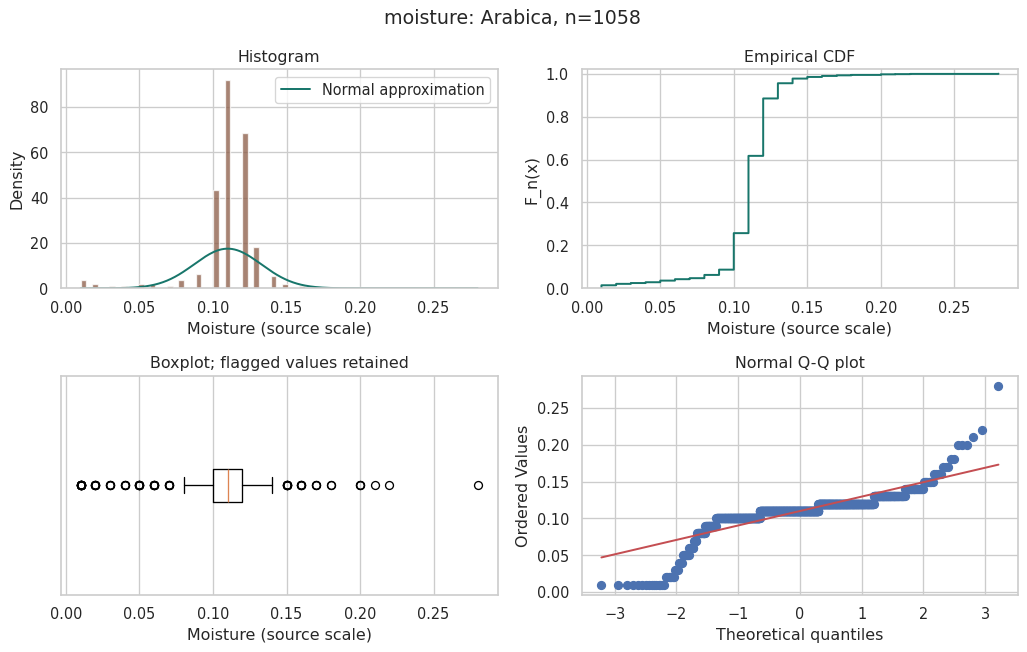

In [5]:
x = data["moisture"].to_numpy()
q1, q3 = np.quantile(x, [0.25, 0.75])
iqr = q3 - q1
flagged = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
summary = pd.Series({"n": len(x), "mean": x.mean(), "median": np.median(x), "variance_ddof1": x.var(ddof=1), "std_ddof1": x.std(ddof=1), "min": x.min(), "q1": q1, "q3": q3, "max": x.max(), "skewness": stats.skew(x, bias=False), "IQR_flags": flagged.sum()})
print(summary.round(5).to_string())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(x, bins="fd", density=True, color="#8a5a44", alpha=0.75)
grid = np.linspace(x.min(), x.max(), 300)
axes[0, 0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std(ddof=1)), color="#18766b", label="Normal approximation")
axes[0, 0].set(xlabel="Moisture (source scale)", ylabel="Density", title="Histogram")
axes[0, 0].legend()
axes[0, 1].step(np.sort(x), np.arange(1, len(x)+1) / len(x), where="post", color="#18766b")
axes[0, 1].set(xlabel="Moisture (source scale)", ylabel="F_n(x)", title="Empirical CDF", ylim=(0, 1.02))
axes[1, 0].boxplot(x, vert=False)
axes[1, 0].set(xlabel="Moisture (source scale)", title="Boxplot; flagged values retained", yticks=[])
stats.probplot(x, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q plot")
fig.suptitle("moisture: Arabica, n=" + str(len(x)))
fig.tight_layout()
plt.show()


### Independence & Estimations

Независимость записей нельзя доказать гистограммой: образцы могут происходить с одних ферм и оцениваться сходным способом. Ниже приведены модельные оценки при предположении независимости; попарные связи показателей исследуются в общем разделе.


In [6]:
print("Нормальность:")
print(normality_table.loc["moisture"].to_string(float_format=lambda value: f"{value:.5g}"))
print("Среднее и интервалы:")
print(interval_table.loc["moisture"].round(5).to_string())
print("Гипотеза нормальности", "отвергается" if normality_table.loc["moisture", "p_holm"] < 0.05 else "не отвергается", "при alpha=0.05 с поправкой Холма.")


Нормальность:
statistic       350.17
p_value     9.1492e-77
p_holm      2.7448e-76
Среднее и интервалы:
n                 1058.00000
mean                 0.11000
t_low                0.10862
t_high               0.11138
bootstrap_low        0.10864
bootstrap_high       0.11133
Гипотеза нормальности отвергается при alpha=0.05 с поправкой Холма.


**Вывод.** n = 1058; среднее 0.11000, медиана 0.11000, стандартное отклонение 0.02279. 95% t-интервал среднего: [0.10862; 0.11138]. Гипотеза нормальности отвергается после поправки Холма (p = 2.74e-76). Это результат для выбранных записей при указанных модельных предположениях.


## Random Variable 02 — Воспринимаемая кислотность

### Description

Оценка того, как дегустатор воспринимает кислотность напитка. Это округлённый сенсорный балл. Два кофе с одинаковым баллом не обязательно имеют одинаковый pH или состав кислот.

Случайная величина: значение `acidity` для выбранной записи Arabica после явно заданного отбора. Наблюдаемые значения округлены; их эмпирическое распределение дискретно.


#### Стохастическая природа оценки кислотности

В столбце `acidity` записан сенсорный балл, а не результат вычисления pH. Протокол каппинга предусматривает оценку качества воспринимаемой кислотности дегустатором. В литературе о сенсорном анализе кофе описаны источники вариации: различия восприятия, привыкание, ожидания и воспроизводимость отдельных сессий [2, 3].

По известным метаданным — например, стране, сорту и способу обработки — нельзя однозначно заранее назначить точный балл конкретной дегустации. Регрессионная модель может дать прогноз с ошибкой, но такой прогноз не является точным законом вычисления наблюдения. Невозможность любой формулы при любом наборе входов мы не доказываем.

**Вывод:** оценку кислотности обоснованно моделировать как случайную величину, зависящую от образца, дегустатора и процедуры оценивания. Это содержательное обоснование; раздельная оценка вариации экспертов и повторных дегустаций в нашем CSV не выполнена.

[2] SCAA. *Cupping Specialty Coffee*, протокол 2009 года, раздел Sample Evaluation. Архивная копия: https://coffeenate.com/wp-content/uploads/2011/09/PR-CUPPING-PROTOCOLS-V.21NOV2009A.pdf

[3] *Prediction of sensory properties of espresso from roasted coffee samples by near-infrared spectroscopy*. Analytica Chimica Acta, 2005. https://www.sciencedirect.com/science/article/pii/S0003267004011171


### EDA & Distribution


n                 1058.00000
mean                 7.52662
median               7.50000
variance_ddof1       0.09867
std_ddof1            0.31411
min                  6.08000
q1                   7.33000
q3                   7.75000
max                  8.75000
skewness             0.11533
IQR_flags           19.00000


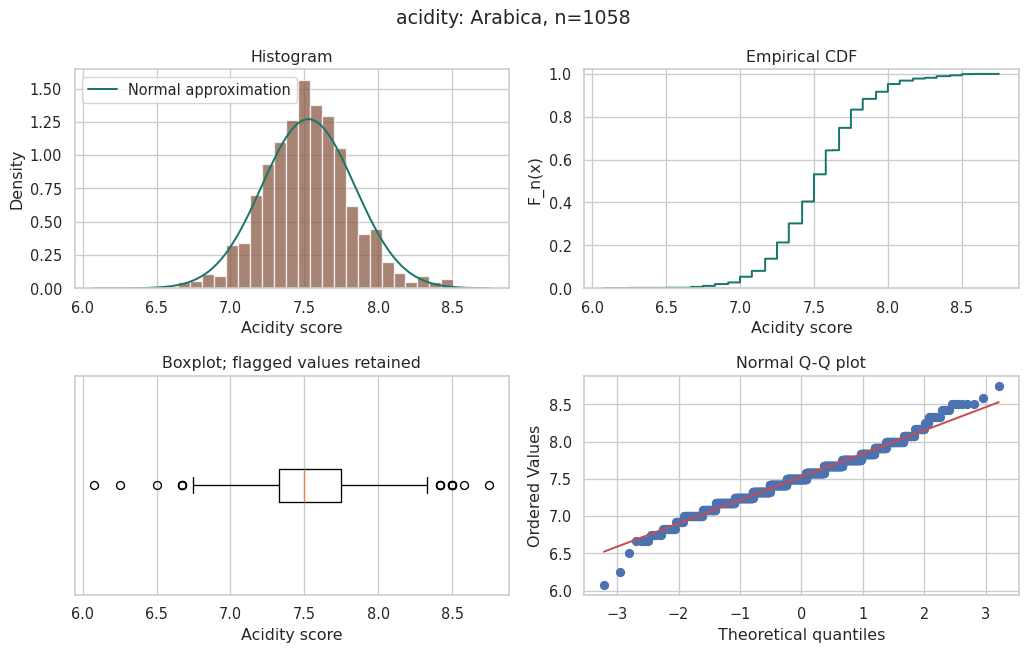

In [7]:
x = data["acidity"].to_numpy()
q1, q3 = np.quantile(x, [0.25, 0.75])
iqr = q3 - q1
flagged = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
summary = pd.Series({"n": len(x), "mean": x.mean(), "median": np.median(x), "variance_ddof1": x.var(ddof=1), "std_ddof1": x.std(ddof=1), "min": x.min(), "q1": q1, "q3": q3, "max": x.max(), "skewness": stats.skew(x, bias=False), "IQR_flags": flagged.sum()})
print(summary.round(5).to_string())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(x, bins="fd", density=True, color="#8a5a44", alpha=0.75)
grid = np.linspace(x.min(), x.max(), 300)
axes[0, 0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std(ddof=1)), color="#18766b", label="Normal approximation")
axes[0, 0].set(xlabel="Acidity score", ylabel="Density", title="Histogram")
axes[0, 0].legend()
axes[0, 1].step(np.sort(x), np.arange(1, len(x)+1) / len(x), where="post", color="#18766b")
axes[0, 1].set(xlabel="Acidity score", ylabel="F_n(x)", title="Empirical CDF", ylim=(0, 1.02))
axes[1, 0].boxplot(x, vert=False)
axes[1, 0].set(xlabel="Acidity score", title="Boxplot; flagged values retained", yticks=[])
stats.probplot(x, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q plot")
fig.suptitle("acidity: Arabica, n=" + str(len(x)))
fig.tight_layout()
plt.show()


### Independence & Estimations

Независимость записей нельзя доказать гистограммой: образцы могут происходить с одних ферм и оцениваться сходным способом. Ниже приведены модельные оценки при предположении независимости; попарные связи показателей исследуются в общем разделе.


In [8]:
print("Нормальность:")
print(normality_table.loc["acidity"].to_string(float_format=lambda value: f"{value:.5g}"))
print("Среднее и интервалы:")
print(interval_table.loc["acidity"].round(5).to_string())
print("Гипотеза нормальности", "отвергается" if normality_table.loc["acidity", "p_holm"] < 0.05 else "не отвергается", "при alpha=0.05 с поправкой Холма.")


Нормальность:
statistic       29.572
p_value     3.7886e-07
p_holm      7.5773e-07
Среднее и интервалы:
n                 1058.00000
mean                 7.52662
t_low                7.50767
t_high               7.54557
bootstrap_low        7.50814
bootstrap_high       7.54521
Гипотеза нормальности отвергается при alpha=0.05 с поправкой Холма.


**Вывод.** n = 1058; среднее 7.52662, медиана 7.50000, стандартное отклонение 0.31411. 95% t-интервал среднего: [7.50767; 7.54557]. Гипотеза нормальности отвергается после поправки Холма (p = 7.58e-07). Это результат для выбранных записей при указанных модельных предположениях.


## Random Variable 03 — Полнота напитка

### Description

Оценка полноты, текстуры и ощущения напитка во рту. Это округлённый сенсорный балл, а не измеренная плотность или вязкость.

Случайная величина: значение `body` для выбранной записи Arabica после явно заданного отбора. Наблюдаемые значения округлены; их эмпирическое распределение дискретно.


#### Стохастическая природа оценки полноты напитка

Столбец `body` содержит сенсорную оценку полноты и текстуры напитка, а не рассчитанную физическую плотность. В протоколе каппинга этот показатель оценивает дегустатор. Для сенсорной процедуры существенны особенности восприятия и воспроизводимость сессий [2, 3].

Конкретный балл `body` нельзя заранее однозначно вычислить по метаданным образца. Даже измеренная плотность или вязкость не тождественны сенсорному баллу. Вероятностная модель учитывает различия образцов, экспертов и условий процедуры; наличие этих компонентов не означает, что любой повтор обязательно даст другой округлённый балл.

**Вывод:** оценку полноты напитка обоснованно моделировать как случайную величину. Для экспериментальной проверки величины вариации оценивания потребовались бы повторные слепые оценки одних образцов, которых в нашей работе нет.

[2] SCAA. *Cupping Specialty Coffee*, протокол 2009 года. https://coffeenate.com/wp-content/uploads/2011/09/PR-CUPPING-PROTOCOLS-V.21NOV2009A.pdf

[3] *Prediction of sensory properties of espresso from roasted coffee samples by near-infrared spectroscopy*. https://www.sciencedirect.com/science/article/pii/S0003267004011171


### EDA & Distribution


n                 1058.00000
mean                 7.50303
median               7.50000
variance_ddof1       0.08159
std_ddof1            0.28564
min                  6.33000
q1                   7.33000
q3                   7.67000
max                  8.58000
skewness             0.05974
IQR_flags           23.00000


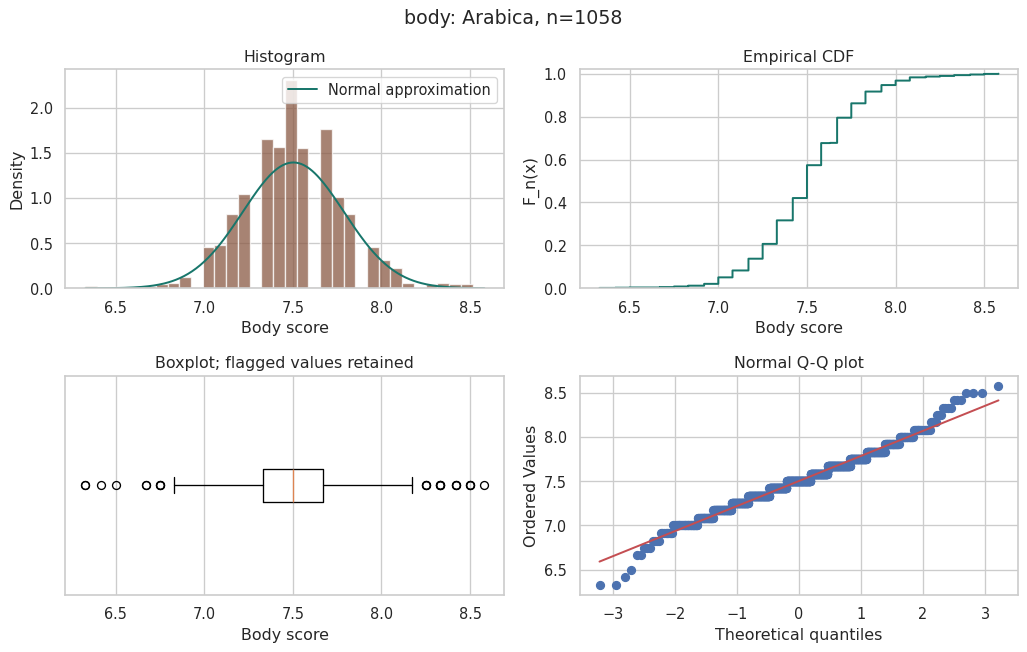

In [9]:
x = data["body"].to_numpy()
q1, q3 = np.quantile(x, [0.25, 0.75])
iqr = q3 - q1
flagged = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)
summary = pd.Series({"n": len(x), "mean": x.mean(), "median": np.median(x), "variance_ddof1": x.var(ddof=1), "std_ddof1": x.std(ddof=1), "min": x.min(), "q1": q1, "q3": q3, "max": x.max(), "skewness": stats.skew(x, bias=False), "IQR_flags": flagged.sum()})
print(summary.round(5).to_string())

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(x, bins="fd", density=True, color="#8a5a44", alpha=0.75)
grid = np.linspace(x.min(), x.max(), 300)
axes[0, 0].plot(grid, stats.norm.pdf(grid, x.mean(), x.std(ddof=1)), color="#18766b", label="Normal approximation")
axes[0, 0].set(xlabel="Body score", ylabel="Density", title="Histogram")
axes[0, 0].legend()
axes[0, 1].step(np.sort(x), np.arange(1, len(x)+1) / len(x), where="post", color="#18766b")
axes[0, 1].set(xlabel="Body score", ylabel="F_n(x)", title="Empirical CDF", ylim=(0, 1.02))
axes[1, 0].boxplot(x, vert=False)
axes[1, 0].set(xlabel="Body score", title="Boxplot; flagged values retained", yticks=[])
stats.probplot(x, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Normal Q-Q plot")
fig.suptitle("body: Arabica, n=" + str(len(x)))
fig.tight_layout()
plt.show()


### Independence & Estimations

Независимость записей нельзя доказать гистограммой: образцы могут происходить с одних ферм и оцениваться сходным способом. Ниже приведены модельные оценки при предположении независимости; попарные связи показателей исследуются в общем разделе.


In [10]:
print("Нормальность:")
print(normality_table.loc["body"].to_string(float_format=lambda value: f"{value:.5g}"))
print("Среднее и интервалы:")
print(interval_table.loc["body"].round(5).to_string())
print("Гипотеза нормальности", "отвергается" if normality_table.loc["body", "p_holm"] < 0.05 else "не отвергается", "при alpha=0.05 с поправкой Холма.")


Нормальность:
statistic        28.17
p_value     7.6388e-07
p_holm      7.6388e-07
Среднее и интервалы:
n                 1058.00000
mean                 7.50303
t_low                7.48580
t_high               7.52027
bootstrap_low        7.48606
bootstrap_high       7.52013
Гипотеза нормальности отвергается при alpha=0.05 с поправкой Холма.


**Вывод.** n = 1058; среднее 7.50303, медиана 7.50000, стандартное отклонение 0.28564. 95% t-интервал среднего: [7.48580; 7.52027]. Гипотеза нормальности отвергается после поправки Холма (p = 7.64e-07). Это результат для выбранных записей при указанных модельных предположениях.


## Критерий 4: EDA и нормализация

**EDA (разведочный анализ)** выполнен в подготовке данных и разделах `EDA & Distribution` каждой величины: проверены объём, виды кофе, пропуски, полные дубликаты и нули; рассчитаны среднее, медиана, дисперсия, стандартное отклонение, квартили, минимум, максимум и асимметрия. Построены гистограммы, эмпирические функции распределения, boxplot и нормальные Q–Q-графики. Парные диаграммы рассеяния и корреляции приведены в следующем разделе.

**Что показал EDA.** В исходной таблице 1339 записей; полных дубликатов нет. Основная выборка после описанного отбора содержит 1058 записей Arabica. У влажности заметна отрицательная асимметрия; сенсорные оценки ближе к симметричным, но их нормальность всё равно отвергается по тесту с поправкой Холма. Правило $1.5IQR$ отмечает 74 значения влажности, 19 значений кислотности и 23 значения полноты напитка. Это количество отмеченных значений по каждому столбцу, а не число разных удалённых строк: все такие наблюдения сохранены. Подозрительные нули обработаны отдельно с анализом чувствительности.

Здесь **нормализацию трактуем как изменение шкалы признаков**. Применяем два явно обозначенных преобразования отдельно к каждому столбцу:

1. **Min–max-нормализация**:
   \[
   u_i=\frac{x_i-x_{min}}{x_{max}-x_{min}}.
   \]
   В подготовленном наборе минимум равен 0, максимум — 1. Масштаб зависит от крайних значений; новые наблюдения вне прежнего диапазона могут выйти за $[0,1]$.
2. **Стандартизация (z-score)**:
   \[
   z_i=\frac{x_i-\bar x}{s},\qquad
   s=\sqrt{\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar x)^2}.
   \]
   Используем `ddof=1`: в подготовленной выборке среднее равно 0, исправленное стандартное отклонение — 1 с учётом точности вычислений.

Исходный `data` сохраняем. Преобразования записываем в отдельные `data_minmax` и `data_zscore`; параметры — в `scaling_parameters`. Ни обрезание, ни удаление крайних значений не выполняем. Boxplot после преобразования позволяет сравнить разброс и хвосты показателей в сопоставимых шкалах.

**Нормализация шкалы не равна приведению к нормальному распределению.** Оба преобразования линейные с положительным коэффициентом: порядок наблюдений, форма распределения, асимметрия и корреляции сохраняются. После них нет оснований объявлять данные нормально распределёнными. Средние, интервалы и содержательные выводы о кофе выше рассчитаны в исходных шкалах.


Параметры преобразований (исходные шкалы):
           min   max      mean  std_ddof1  range
moisture  0.01  0.28  0.110000   0.022794   0.27
acidity   6.08  8.75  7.526616   0.314114   2.67
body      6.33  8.58  7.503034   0.285637   2.25

Проверка диапазона, стандартизации и сохранения асимметрии:
          minmax_min  minmax_max  z_mean  z_std_ddof1  skew_original  skew_minmax  skew_zscore
moisture         0.0         1.0    -0.0          1.0      -1.109243    -1.109243    -1.109243
acidity          0.0         1.0     0.0          1.0       0.115326     0.115326     0.115326
body             0.0         1.0    -0.0          1.0       0.059739     0.059739     0.059739


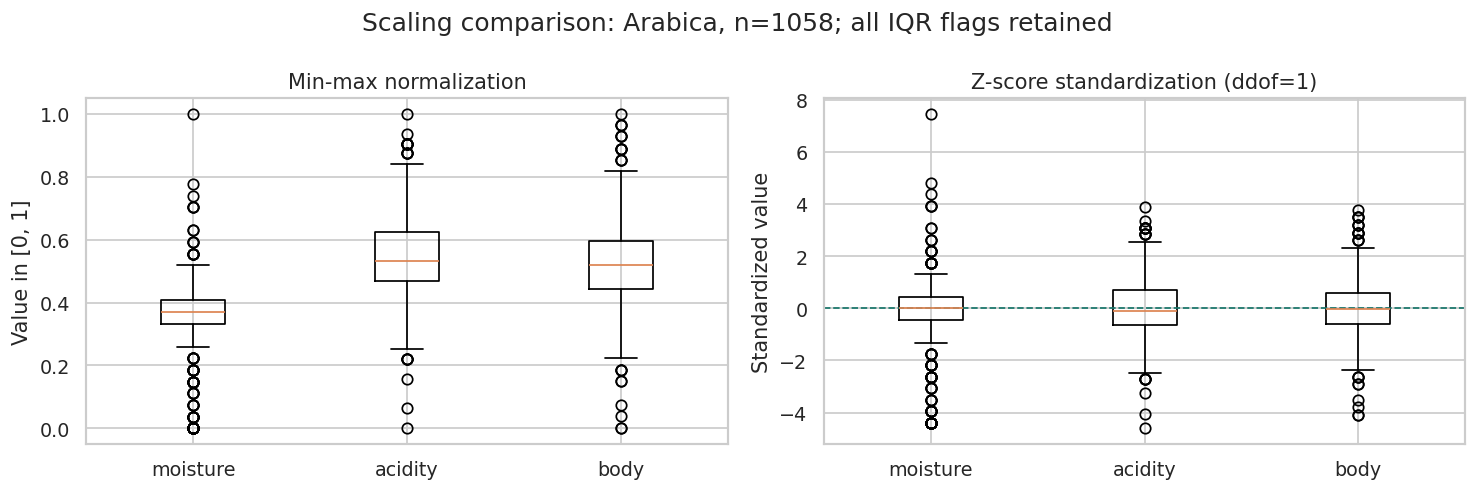

In [11]:
# Две отдельные версии данных; исходная таблица data не изменяется.
source_features = data[columns].copy()
scaling_parameters = pd.DataFrame({
    "min": source_features.min(),
    "max": source_features.max(),
    "mean": source_features.mean(),
    "std_ddof1": source_features.std(ddof=1),
})
scaling_parameters["range"] = scaling_parameters["max"] - scaling_parameters["min"]
assert scaling_parameters["range"].gt(0).all()
assert scaling_parameters["std_ddof1"].gt(0).all()
data_minmax = (source_features - scaling_parameters["min"]) / scaling_parameters["range"]
data_zscore = (source_features - scaling_parameters["mean"]) / scaling_parameters["std_ddof1"]

scaling_checks = pd.DataFrame({
    "minmax_min": data_minmax.min(),
    "minmax_max": data_minmax.max(),
    "z_mean": data_zscore.mean(),
    "z_std_ddof1": data_zscore.std(ddof=1),
    "skew_original": source_features.skew(),
    "skew_minmax": data_minmax.skew(),
    "skew_zscore": data_zscore.skew(),
})
print("Параметры преобразований (исходные шкалы):")
print(scaling_parameters.round(6).to_string())
print("\nПроверка диапазона, стандартизации и сохранения асимметрии:")
print(scaling_checks.round(6).to_string())
assert np.allclose(data_minmax.min(), 0)
assert np.allclose(data_minmax.max(), 1)
assert np.allclose(data_zscore.mean(), 0, atol=1e-12)
assert np.allclose(data_zscore.std(ddof=1), 1)
assert np.allclose(source_features.skew(), data_zscore.skew())
assert np.allclose(source_features.corr(), data_minmax.corr())
assert np.allclose(source_features.corr(), data_zscore.corr())
assert data[columns].equals(source_features)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, transformed, title, ylabel in [
    (axes[0], data_minmax, "Min-max normalization", "Value in [0, 1]"),
    (axes[1], data_zscore, "Z-score standardization (ddof=1)", "Standardized value"),
]:
    axis.boxplot([transformed[column].to_numpy() for column in columns])
    axis.set_xticks(np.arange(1, len(columns) + 1))
    axis.set_xticklabels(columns)
    axis.set(title=title, ylabel=ylabel)
axes[1].axhline(0, color="#18766b", linestyle="--", linewidth=1)
fig.suptitle(f"Scaling comparison: Arabica, n={len(data)}; all IQR flags retained")
fig.tight_layout()
plt.show()


### Вывод по EDA и нормализации

Оба преобразования выполнены для всех 1058 наблюдений каждого показателя. Проверки подтвердили диапазон $[0,1]$ после min–max и среднее 0 / стандартное отклонение 1 после z-score. Асимметрия осталась прежней: приблизительно −1.109 для влажности, 0.115 для кислотности и 0.060 для полноты напитка. Корреляционная матрица также сохранилась.

На общей шкале видны крайние значения влажности; min–max сжимает основную часть этого распределения из-за крайних наблюдений. Стандартизация удобна для сравнения отклонений от среднего в единицах стандартного отклонения, но не устраняет хвосты и чувствительность к крайним значениям. Результаты проверки нормальности исходных данных не изменяются от такого масштабирования. Приведение распределений к гауссовой форме этими преобразованиями не выполняется и для описательного анализа не требуется.


## Связи между показателями

Изучаем все три пары. Коэффициент Пирсона описывает линейную связь, Спирмена — монотонную. Для каждой семьи из трёх проверок отдельно применяем поправку Холма. Нулевая гипотеза теста корреляции не равнозначна общей гипотезе независимости: нулевая корреляция может существовать при нелинейной зависимости.

Используем двусторонние тесты. Их p-значения условны относительно модели независимых наблюдений и не являются вероятностью истинности нулевой гипотезы. Значимость связи не говорит о её причинности или практической силе.


                    pearson_r   pearson_p  spearman_rho  spearman_p  pearson_p_holm  spearman_p_holm
pair                                                                                                
moisture / acidity    -0.1816  2.6889e-09      -0.18017  3.5944e-09      2.6889e-09       4.7173e-09
moisture / body      -0.18872  6.1319e-10      -0.18225  2.3587e-09      1.2264e-09       4.7173e-09
acidity / body        0.65442 2.3604e-130       0.62357 4.8388e-115     7.0812e-130      1.4516e-114


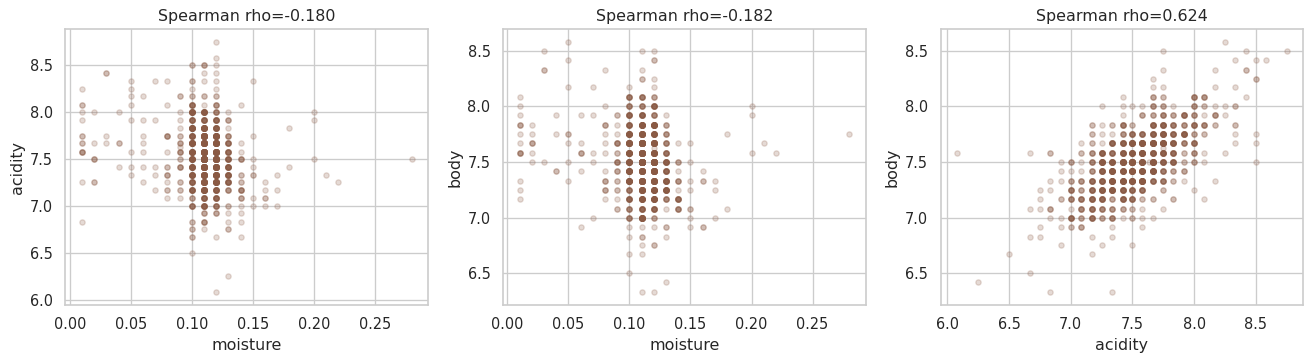

In [12]:
pairs = [("moisture", "acidity"), ("moisture", "body"), ("acidity", "body")]
correlation_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for axis, (first, second) in zip(axes, pairs):
    pearson = stats.pearsonr(data[first], data[second])
    spearman = stats.spearmanr(data[first], data[second])
    correlation_rows.append({"pair": first + " / " + second, "pearson_r": pearson.statistic, "pearson_p": pearson.pvalue, "spearman_rho": spearman.statistic, "spearman_p": spearman.pvalue})
    axis.scatter(data[first], data[second], s=16, alpha=0.22, color="#8a5a44")
    axis.set(xlabel=first, ylabel=second, title=f"Spearman rho={spearman.statistic:.3f}")
fig.tight_layout()
plt.show()
correlation_table = pd.DataFrame(correlation_rows).set_index("pair")
correlation_table["pearson_p_holm"] = holm_adjust(correlation_table["pearson_p"])
correlation_table["spearman_p_holm"] = holm_adjust(correlation_table["spearman_p"])
print(correlation_table.to_string(float_format=lambda value: f"{value:.5g}"))


## Критерий 2: зависимость величин одной природы

`acidity` и `body` имеют общую природу события: это две сенсорные оценки одного образца кофе в рамках каппинга. По условию нужно установить независимость **или зависимость**; добиваться независимости искусственным изменением данных не требуется.

Проверяем гипотезы:

\[
H_0:\; A\text{ и }B\text{ независимы};\qquad
H_1:\; A\text{ и }B\text{ зависимы},\qquad \alpha=0.05.
\]

Для независимости необходимо, чтобы для любых множеств значений \(U,V\)

\[
P(A\in U,B\in V)=P(A\in U)P(B\in V).
\]

В качестве иллюстрации проверим это равенство для событий \(A\ge7.5\), \(B\ge7.5\) в эмпирическом распределении. Его нарушение доказывает зависимость именно в распределении, полученном равновероятным выбором одной строки этой подготовленной таблицы. Перенос вывода на более широкую совокупность требует дополнительных предположений.

Для статистического вывода используем **перестановочный тест** с модулем коэффициента Спирмена. При \(H_0\) и предположении iid-пар переупорядочивание значений `body` относительно `acidity` сохраняет условное распределение данных при независимости. Ранги вычисляем с усреднением совпадающих значений. В каждой из 9999 перестановок заново составляем пары и рассчитываем ранговую корреляцию. Двустороннюю экстремальность определяем по модулю коэффициента:

\[
p_{MC}=\frac{1+\#\{|\rho_s^{(b)}|\ge|\rho_s^{obs}|\}}{9999+1}.
\]

Ранжирование не требует нормальности исходных баллов. Нулевая ранговая корреляция сама по себе **не доказывала бы** независимость: этот тест чувствителен прежде всего к монотонной связи. При наблюдаемой положительной связи он позволяет отвергнуть независимость в указанной модели.

Основной тест относится к заданной критерием паре `acidity`/`body`. Дополнительно показываем консервативное значение \(\min(1,3p_{MC})\), если рассматривать тест как часть анализа трёх пар показателей (поправка Бонферрони). Это отдельно от уже приведённой поправки Холма для асимптотических корреляционных тестов.

Методические источники: [SciPy: Spearman correlation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html), [SciPy: перестановки пар](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html), [Penn State: независимость и корреляция](https://online.stat.psu.edu/stat414/Lesson18).


In [13]:
# Две сенсорные оценки одной и той же партии: строки остаются парными.
criterion2_a = data["acidity"].to_numpy()
criterion2_b = data["body"].to_numpy()
criterion2_n = len(criterion2_a)

criterion2_event_a = criterion2_a >= 7.5
criterion2_event_b = criterion2_b >= 7.5
criterion2_pa = criterion2_event_a.mean()
criterion2_pb = criterion2_event_b.mean()
criterion2_pab = (criterion2_event_a & criterion2_event_b).mean()
print("Иллюстрация для эмпирического распределения:")
print(f"P(acidity >= 7.5) = {criterion2_pa:.6f}")
print(f"P(body >= 7.5) = {criterion2_pb:.6f}")
print(f"P(оба события) = {criterion2_pab:.6f}")
print(f"Произведение вероятностей = {criterion2_pa * criterion2_pb:.6f}")

# Корреляция рангов с усреднением связок — коэффициент Спирмена.
criterion2_rank_a = stats.rankdata(criterion2_a, method="average")
criterion2_rank_b = stats.rankdata(criterion2_b, method="average")
criterion2_rank_a = criterion2_rank_a - criterion2_rank_a.mean()
criterion2_rank_b = criterion2_rank_b - criterion2_rank_b.mean()
criterion2_scale = np.linalg.norm(criterion2_rank_a) * np.linalg.norm(criterion2_rank_b)
criterion2_rho = np.dot(criterion2_rank_a, criterion2_rank_b) / criterion2_scale

criterion2_rng = np.random.default_rng(42)
criterion2_repetitions = 9999
criterion2_extreme = 0
for _ in range(criterion2_repetitions):
    criterion2_permuted = criterion2_rng.permutation(criterion2_rank_b)
    criterion2_rho_null = np.dot(criterion2_rank_a, criterion2_permuted) / criterion2_scale
    if abs(criterion2_rho_null) >= abs(criterion2_rho) - 1e-12:
        criterion2_extreme += 1
criterion2_p_mc = (criterion2_extreme + 1) / (criterion2_repetitions + 1)
criterion2_p_bonf = min(1.0, 3 * criterion2_p_mc)

print("\nПерестановочная проверка независимости:")
print(f"n = {criterion2_n}; Spearman rho = {criterion2_rho:.6f}")
print(f"Перестановок = {criterion2_repetitions}; не менее экстремальных = {criterion2_extreme}")
print(f"Monte Carlo p-value = {criterion2_p_mc:.6f}")
print(f"С поправкой Бонферрони на три пары = {criterion2_p_bonf:.6f}")
print("H0 независимости", "отвергается" if criterion2_p_bonf < 0.05 else "не отвергается", "при alpha = 0.05.")


Иллюстрация для эмпирического распределения:
P(acidity >= 7.5) = 0.595463
P(body >= 7.5) = 0.579395
P(оба события) = 0.443289
Произведение вероятностей = 0.345008

Перестановочная проверка независимости:
n = 1058; Spearman rho = 0.623569
Перестановок = 9999; не менее экстремальных = 0
Monte Carlo p-value = 0.000100
С поправкой Бонферрони на три пары = 0.000300
H0 независимости отвергается при alpha = 0.05.


**Результат.** Для 1058 записей Arabica получено \(\rho_s=0.6236\). Из 9999 случайных перестановок 0 дали не менее экстремальную корреляцию по модулю. Monte Carlo p-value с поправкой «+1» составляет 0.0001, а консервативное значение после поправки на три пары — 0.0003. Оба значения меньше 0.05: гипотеза независимости отвергается в модели независимых и одинаково распределённых пар наблюдений.

**Интерпретация.** Выявлена выраженная положительная монотонная связь: более высокие оценки кислотности чаще сочетаются с более высокими оценками полноты напитка. Эти два показателя нельзя считать независимыми по результатам анализа. Из этого не следует, что кислотность причинно определяет полноту напитка: возможны общие свойства кофе, общий стиль оценивания эксперта и другие факторы.

В эмпирическом распределении вероятность совместного события равна 0.443289, а произведение вероятностей — 0.345008. Их неравенство непосредственно показывает зависимость в модели равновероятного выбора строки текущей таблицы.

**Точность и ограничения.** При 9999 перестановках минимальное ненулевое Monte Carlo p-value в выбранной схеме равно 0.0001. Полученное число не означает, что точное p-value известно с такой точностью; оно может быть существенно меньше. Зависимость разных показателей одной строки не следует путать с независимостью строк между собой. Общие фермы, страны и оценщики могут нарушать обменность строк; перестановочный вывод условен относительно этого предположения. Ранее выполненный анализ чувствительности с сохранением нулей влажности даёт сходную связь сенсорных оценок, но также не проверяет независимость строк.


## Анализ чувствительности к нулевой влажности

Сравниваем средние сенсорных баллов и их связь в двух вариантах: основная выборка с положительной влажностью и Arabica с положительными сенсорными оценками независимо от влажности. Эта проверка не восстанавливает пропущенные измерения и не исключает смещение; она показывает, насколько конкретный фильтр меняет наблюдаемые результаты.


In [14]:
sensory_base = arabica.dropna(subset=["acidity", "body"])
sensory_base = sensory_base.loc[sensory_base[["acidity", "body"]].gt(0).all(axis=1)]
sensitivity_rows = []
for label, subset in [("positive moisture", data), ("moisture zeros retained", sensory_base)]:
    sensitivity_rows.append({"sample": label, "n": len(subset), "acidity_mean": subset["acidity"].mean(), "body_mean": subset["body"].mean(), "acidity_body_rho": stats.spearmanr(subset["acidity"], subset["body"]).statistic})
sensitivity_table = pd.DataFrame(sensitivity_rows).set_index("sample")
print(sensitivity_table.round(5).to_string())


                            n  acidity_mean  body_mean  acidity_body_rho
sample                                                                  
positive moisture        1058       7.52662    7.50303           0.62357
moisture zeros retained  1310       7.53886    7.52347           0.61543


## Критерий 3: эмпирическая состоятельность оценок

Оценка $\widehat\theta_n$ состоятельна, если для любого $\varepsilon>0$
\[
P(|\widehat\theta_n-\theta|>\varepsilon)\longrightarrow 0\quad(n\to\infty).
\]
Проверяем **выборочное среднее** $\bar X_n$ как оценку математического ожидания и **исправленную выборочную дисперсию** $S_n^2$ как оценку дисперсии — для каждого из трёх показателей. Состоятельность характеризует последовательность оценок при росте объёма, а не отдельное вычисленное число; одна удачная траектория среднего недостаточна.

**Модель эксперимента.** 1058 подготовленных строк задают эмпирическое распределение: каждую строку независимо выбираем с возвращением с вероятностью $1/1058$. Известные параметры этой модели — среднее полного набора $\mu_{emp}$ и его дисперсия $\sigma_{emp}^2$ с делителем 1058 (`ddof=0`). В повторных выборках дисперсию оцениваем с делителем $n-1$ (`ddof=1`). Выборки с возвращением могут содержать больше 1058 наблюдений, но не добавляют новых реальных данных.

Для каждого $n\in\{20,50,100,250,500,1000,5000\}$ генерируем **1000 повторных выборок**. Для обеих оценок считаем:

- смещение по повторениям и $RMSE=\sqrt{\operatorname{mean}((\widehat\theta_n-\theta_{emp})^2)}$;
- долю повторений с $|\widehat\theta_n-\theta_{emp}|>\varepsilon$; пороги фиксированы при всех $n$: $\varepsilon_\mu=0.25\sigma_{emp}$ и $\varepsilon_v=0.25\sigma_{emp}^2$;
- нормированный RMSE для сопоставления разных шкал.

Порог 25% выбран для иллюстрации, а не как допустимая ошибка лабораторного измерения. Конечный эксперимент не проверяет все $\varepsilon$ и все $n$, но показывает ожидаемое поведение.

**Теоретическая опора.** Для iid-наблюдений с конечной дисперсией среднее состоятельно по закону больших чисел. У нашего конечного эмпирического распределения существуют все моменты. Для него $MSE(\bar X_n)=\sigma_{emp}^2/n$, а
\[
MSE(S_n^2)=\frac1n\left(\mu_{4,emp}-\frac{n-3}{n-1}\sigma_{emp}^4\right)\longrightarrow0,
\]
где $\mu_{4,emp}=E_{emp}[(X-\mu_{emp})^4]$. Обе оценки здесь несмещённые, поэтому MSE равен их дисперсии. По неравенству Чебышёва $P(|\widehat\theta_n-\theta_{emp}|>\varepsilon)\le MSE(\widehat\theta_n)/\varepsilon^2\to0$. Пунктир на графиках показывает теоретический RMSE именно этой модели.

Независимость **строк** при таком моделировании задана процедурой отбора. Зависимость `acidity` и `body` внутри одной строки этому не мешает. Эксперимент не устанавливает независимость реальных образцов CQI и репрезентативность набора для всего кофе.


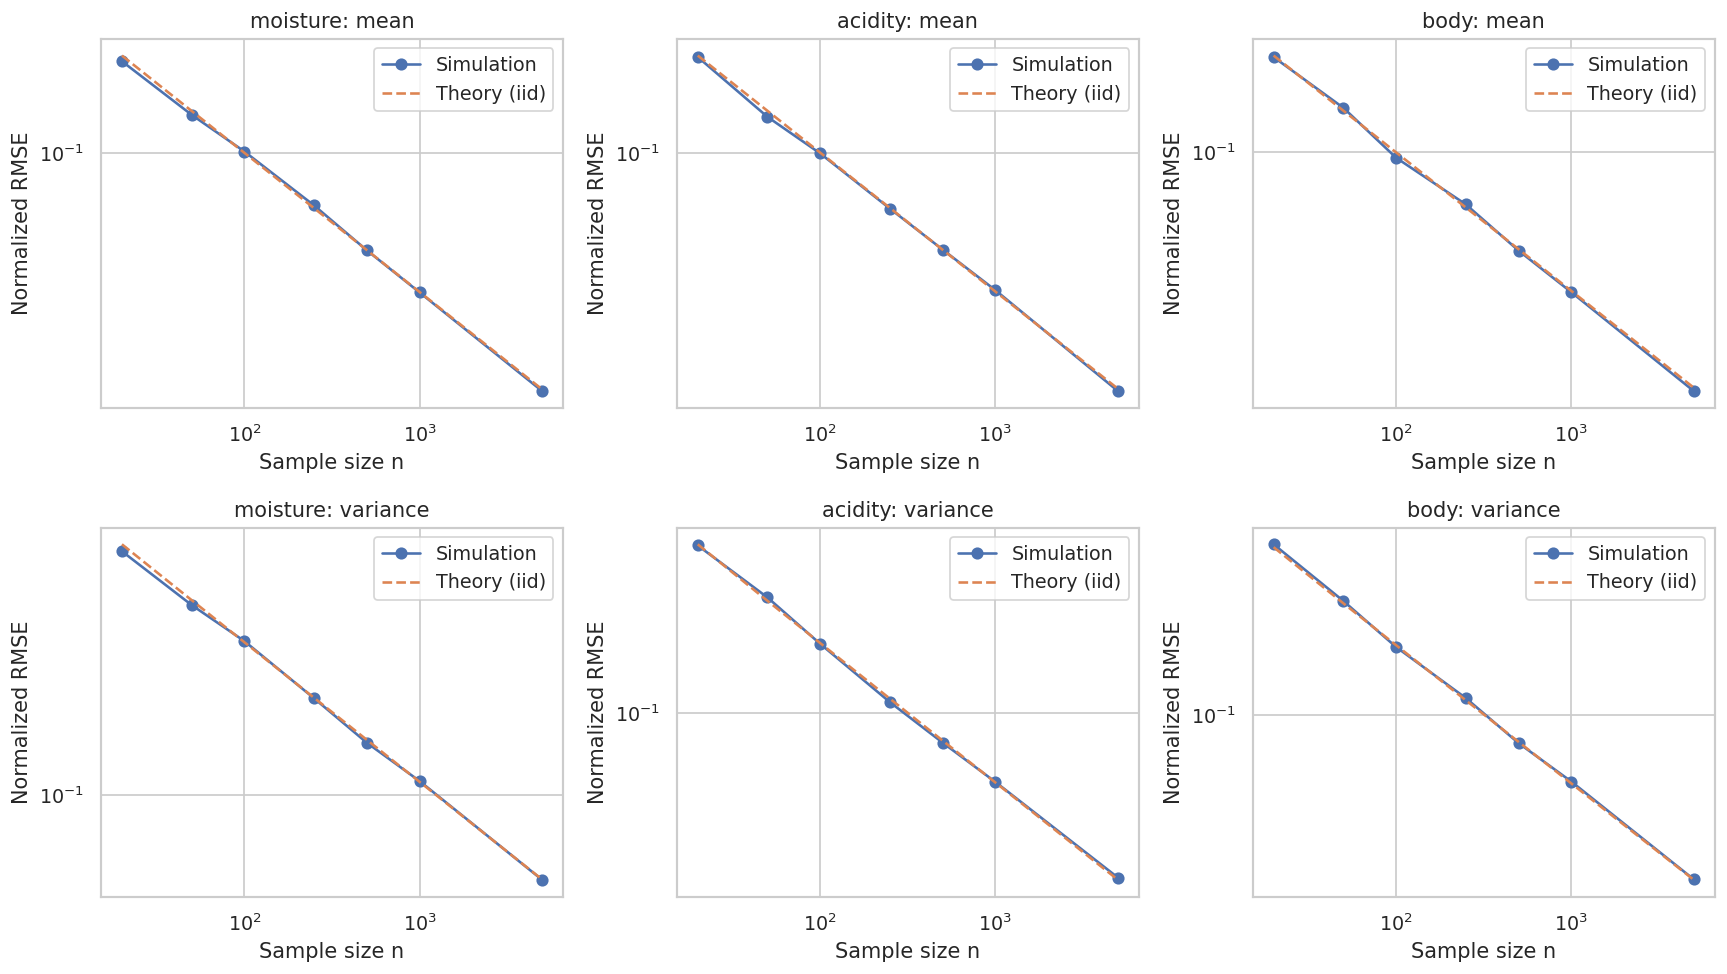

Повторений для каждого объёма: 1000
Средние: нормировка на sigma_emp; дисперсии: на variance_emp.
variable estimator    n   target      bias     RMSE  normalized_RMSE  epsilon  P_error_gt_epsilon
moisture      mean   20 0.110000  0.000081 0.004860         0.213297 0.005696               0.208
moisture  variance   20 0.000519 -0.000025 0.000389         0.749543 0.000130               0.775
moisture      mean   50 0.110000 -0.000063 0.003120         0.136949 0.005696               0.073
moisture  variance   50 0.000519  0.000000 0.000250         0.480974 0.000130               0.607
moisture      mean  100 0.110000 -0.000033 0.002304         0.101105 0.005696               0.020
moisture  variance  100 0.000519  0.000006 0.000185         0.357135 0.000130               0.476
moisture      mean  250 0.110000  0.000001 0.001474         0.064698 0.005696               0.000
moisture  variance  250 0.000519  0.000005 0.000116         0.222711 0.000130               0.263
moisture      mean  

In [15]:
sizes = np.array([20, 50, 100, 250, 500, 1000, 5000])
repetitions = 1000
simulation_rng = np.random.default_rng(SEED)
simulation_rows = []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for column_index, column in enumerate(columns):
    values = data[column].to_numpy()
    mean_target = values.mean()
    variance_target = values.var(ddof=0)
    sigma = np.sqrt(variance_target)
    fourth_moment = np.mean((values - mean_target)**4)
    for size in sizes:
        samples = simulation_rng.choice(values, size=(repetitions, size), replace=True)
        estimates_by_kind = {
            "mean": samples.mean(axis=1),
            "variance": samples.var(axis=1, ddof=1),
        }
        for estimator, estimates in estimates_by_kind.items():
            target = mean_target if estimator == "mean" else variance_target
            scale = sigma if estimator == "mean" else variance_target
            epsilon = 0.25 * scale
            errors = estimates - target
            theory_mse = (variance_target / size if estimator == "mean" else
                          (fourth_moment - (size - 3) / (size - 1) * variance_target**2) / size)
            simulation_rows.append({
                "variable": column, "estimator": estimator, "n": size,
                "target": target, "bias": errors.mean(),
                "RMSE": np.sqrt(np.mean(errors**2)),
                "normalized_RMSE": np.sqrt(np.mean(errors**2)) / scale,
                "theory_normalized_RMSE": np.sqrt(theory_mse) / scale,
                "epsilon": epsilon,
                "P_error_gt_epsilon": np.mean(np.abs(errors) > epsilon),
            })
    variable_results = pd.DataFrame(simulation_rows)
    for row_index, estimator in enumerate(["mean", "variance"]):
        subset = variable_results.loc[
            variable_results["variable"].eq(column) & variable_results["estimator"].eq(estimator)
        ]
        axis = axes[row_index, column_index]
        axis.loglog(subset["n"], subset["normalized_RMSE"], "o-", label="Simulation")
        axis.loglog(subset["n"], subset["theory_normalized_RMSE"], "--", label="Theory (iid)")
        axis.set(xlabel="Sample size n", ylabel="Normalized RMSE", title=f"{column}: {estimator}")
        axis.legend()
fig.tight_layout()
plt.show()
simulation_table = pd.DataFrame(simulation_rows)
print(f"Повторений для каждого объёма: {repetitions}")
print("Средние: нормировка на sigma_emp; дисперсии: на variance_emp.")
print(simulation_table.drop(columns=["theory_normalized_RMSE"]).round(6).to_string(index=False))


### Вывод по критерию 3

Результаты при увеличении $n$ с 20 до 5000 (порог ошибки для каждой оценки не меняется):

| Показатель | Оценка | RMSE: n=20 → n=5000 | Доля ошибок больше ε: n=20 → n=5000 |
| --- | --- | --- | --- |
| moisture | среднее | 0.00485968 → 0.000317564 | 20.8% → 0.0% |
| moisture | дисперсия | 0.000389082 → 2.58698e-05 | 77.5% → 0.0% |
| acidity | среднее | 0.0693622 → 0.00435593 | 24.3% → 0.0% |
| acidity | дисперсия | 0.0394792 → 0.00252637 | 51.8% → 0.0% |
| body | среднее | 0.0630401 → 0.00392457 | 24.4% → 0.0% |
| body | дисперсия | 0.0338251 → 0.00206265 | 55.0% → 0.0% |

Для средних и исправленных дисперсий всех трёх величин RMSE уменьшается и согласуется с теоретическими кривыми. Доля ошибок больше фиксированного порога также уменьшается. Это **эмпирически подтверждает ожидаемую состоятельность обеих оценок в принятой iid-модели эмпирического распределения**. Из-за случайности моделирования отдельные соседние значения не обязаны убывать строго.

Нулевая наблюдаемая доля ошибок означает только отсутствие таких ошибок в 1000 повторениях, а не нулевую вероятность. Истинные параметры реальной совокупности кофе неизвестны; среднее и дисперсия полного датасета здесь — точные параметры только эмпирической модели. Поэтому эксперимент не доказывает точность оценок для всего мирового кофе.


## Критерий 5: генеральная совокупность и два способа отбора

**Объект вывода.** В этом учебном эксперименте конечная генеральная совокупность — все **1058 подготовленных записей Arabica** (`population = data[columns]`). Это заданная рамка отбора, а не вся арабика мира. В предыдущих разделах те же записи назывались основной выборкой относительно реального производства кофе; здесь их роль меняется: из полностью известной таблицы берём меньшие выборки и проверяем качество восстановления её параметров. Результаты относятся к этой конечной совокупности и выбранному правилу подготовки.

Берём по **300 записей** двумя способами, с фиксированным seed без подбора удачного результата:

- **С возвращением:** при каждом из 300 извлечений любая строка имеет вероятность $1/N$; одна строка может попасть несколько раз. Повторы сохраняем, иначе изменится схема отбора.
- **Без возвращения:** выбираем 300 разных строк; каждое подмножество такого размера равновероятно, вероятность включения каждой строки — $n/N$. Извлечения зависимы из-за запрета повторов. Такой отбор не требует предположения iid о реальном происхождении записей для вывода о фиксированной конечной таблице.

Отбираем **целые строки**, сохраняя пары `moisture`, `acidity`, `body`. Одинаковые численные оценки в разных строках не означают повторный выбор одной строки. Случайная схема позволяет оценивать параметры совокупности с известной погрешностью; она не гарантирует совпадение статистик каждой отдельной выборки.

### Сравнение статистик и погрешности

Рассчитываем среднее, медиану, дисперсию, стандартное отклонение, квартили и диапазон для совокупности и обеих выборок. Для среднего и дисперсии показываем ошибки относительно известных параметров.

Различаем две записи дисперсии конечной совокупности:
\[
\mu_N=\frac1N\sum X_i,\qquad
\sigma_N^2=\frac1N\sum(X_i-\mu_N)^2,\qquad
S_N^2=\frac1{N-1}\sum(X_i-\mu_N)^2.
\]
При отборе с возвращением $s^2$ (`ddof=1`) несмещённо оценивает $\sigma_N^2$. Без возвращения оно несмещённо оценивает $S_N^2$, поэтому для сопоставления с одним параметром $\sigma_N^2$ используем $\widehat\sigma_N^2=(N-1)s^2/N$. В таблице выводим и обычное $s^2$, и приведённую к общей цели оценку.

Точная стандартная ошибка среднего при известной совокупности:
\[
SE_{WR}=\frac{\sigma_N}{\sqrt n},\qquad
SE_{WOR}=\frac{\sigma_N}{\sqrt n}\sqrt{\frac{N-n}{N-1}}.
\]
Для интервала используем **только выборочную** оценку ошибки: $\widehat{SE}_{WR}=s/\sqrt n$ и $\widehat{SE}_{WOR}=s\sqrt{1-n/N}/\sqrt n$. Это две согласованные формы поправки с разными делителями дисперсии; смешивать их нельзя.

Строим приближённые 95% интервалы $\bar x\pm1.96\widehat{SE}$ и проверяем, попало ли в них известное $\mu_N$. Интервалы основаны на нормальном приближении для распределения среднего, а не на нормальности исходных наблюдений; точное 95% покрытие не обещается. Каждый интервал относится к одному показателю отдельно, не к одновременному покрытию трёх средних.

Дополнительно повторяем обе схемы по **1000 раз при том же n=300**, сравнивая смещение, RMSE среднего, теоретическую стандартную ошибку, RMSE оценки дисперсии и долю интервалов, покрывших $\mu_N$. Это позволяет оценить схему, а не только одну удачную или неудачную выборку. Статистический тест двух независимых групп для сравнения подвыборки с её родительской таблицей здесь не нужен.

Методические источники: [UC Berkeley: оценка параметров и поправка на конечную совокупность](https://www.stat.berkeley.edu/~stark/SticiGui/Text/estimation.htm), [Penn State: простая случайная выборка](https://online.stat.psu.edu/stat506/Lesson01).


Конечная генеральная совокупность: N=1058; n=300 (28.4% N)

Схемы отбора:
                     draws  unique_rows  repeated_draws
design                                                 
with replacement       300          263              37
without replacement    300          300               0

Известные статистики генеральной совокупности:
             N      mean  median  variance_N  variance_N_minus_1     std_N    q1    q3   min   max
moisture  1058  0.110000    0.11    0.000519            0.000520  0.022784  0.10  0.12  0.01  0.28
acidity   1058  7.526616    7.50    0.098574            0.098667  0.313965  7.33  7.75  6.08  8.75
body      1058  7.503034    7.50    0.081511            0.081588  0.285502  7.33  7.67  6.33  8.58

Статистики отдельных выборок и ошибки относительно генеральной совокупности:
             design variable   n     mean  median  s2_ddof1  variance_estimate_for_N  std_ddof1   q1   q3  min  max  mean_error  variance_error  SE_estimate  CI95_low  CI95_high  c

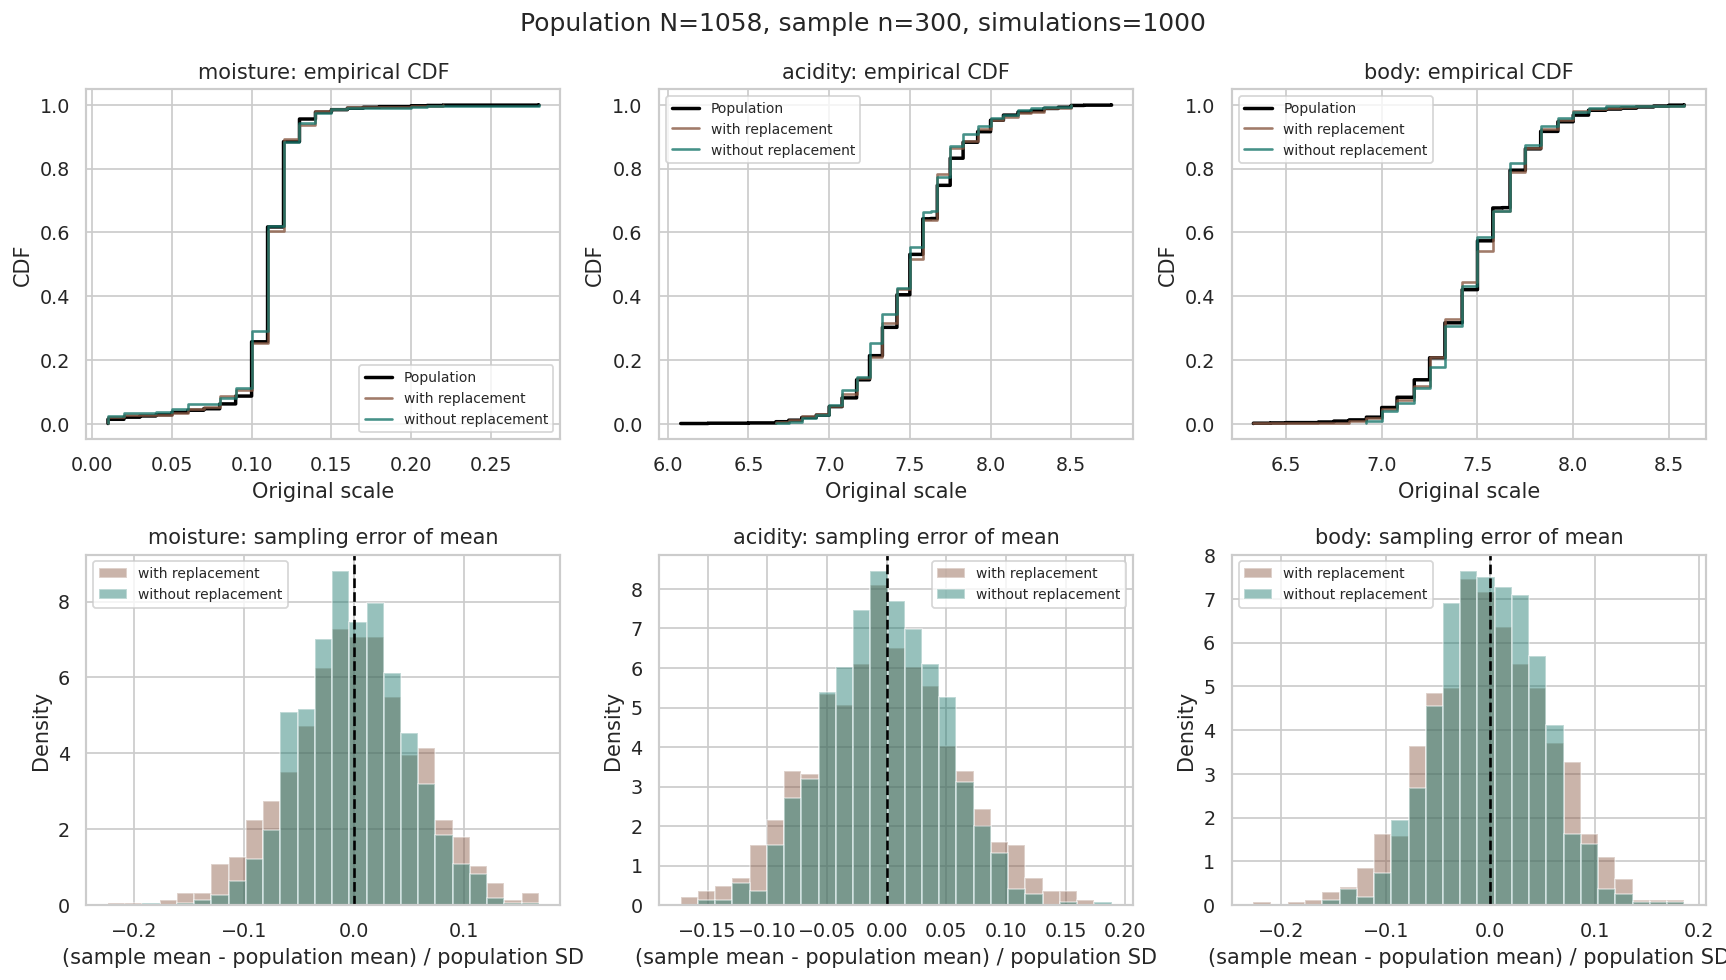

In [16]:
population = data[columns].copy()
population_n = len(population)
sample_n = 300
assert 1 < sample_n < population_n
sampling_designs = [("with replacement", True), ("without replacement", False)]
sampling_rng = np.random.default_rng(SEED + 500)
sample_positions = {
    label: sampling_rng.choice(population_n, size=sample_n, replace=replace)
    for label, replace in sampling_designs
}
samples_by_design = {
    label: population.iloc[positions].copy()
    for label, positions in sample_positions.items()
}
sampling_design_table = pd.DataFrame([
    {"design": label, "draws": sample_n, "unique_rows": len(np.unique(positions)),
     "repeated_draws": sample_n - len(np.unique(positions))}
    for label, positions in sample_positions.items()
]).set_index("design")
assert sampling_design_table.loc["without replacement", "unique_rows"] == sample_n
population_stats = pd.DataFrame({
    "N": population_n, "mean": population.mean(), "median": population.median(),
    "variance_N": population.var(ddof=0), "variance_N_minus_1": population.var(ddof=1),
    "std_N": population.std(ddof=0), "q1": population.quantile(.25),
    "q3": population.quantile(.75), "min": population.min(), "max": population.max(),
})
sampling_comparison_rows = []
for label, replace in sampling_designs:
    sample = samples_by_design[label]
    for column in columns:
        values = sample[column].to_numpy()
        target_mean = population_stats.loc[column, "mean"]
        target_variance = population_stats.loc[column, "variance_N"]
        s2 = values.var(ddof=1)
        variance_estimate = s2 if replace else (population_n - 1) / population_n * s2
        correction = 1 if replace else np.sqrt(1 - sample_n / population_n)
        se_estimate = np.sqrt(s2 / sample_n) * correction
        low, high = values.mean() + np.array([-1, 1]) * stats.norm.ppf(.975) * se_estimate
        sampling_comparison_rows.append({
            "design": label, "variable": column, "n": len(values),
            "mean": values.mean(), "median": np.median(values), "s2_ddof1": s2,
            "variance_estimate_for_N": variance_estimate, "std_ddof1": np.sqrt(s2),
            "q1": np.quantile(values, .25), "q3": np.quantile(values, .75),
            "min": values.min(), "max": values.max(),
            "mean_error": values.mean() - target_mean,
            "variance_error": variance_estimate - target_variance,
            "SE_estimate": se_estimate, "CI95_low": low, "CI95_high": high,
            "covers_population_mean": bool(low <= target_mean <= high),
        })
sampling_comparison = pd.DataFrame(sampling_comparison_rows)
print(f"Конечная генеральная совокупность: N={population_n}; n={sample_n} ({sample_n/population_n:.1%} N)")
print("\nСхемы отбора:")
print(sampling_design_table.to_string())
print("\nИзвестные статистики генеральной совокупности:")
print(population_stats.round(6).to_string())
print("\nСтатистики отдельных выборок и ошибки относительно генеральной совокупности:")
print(sampling_comparison.round(6).to_string(index=False))

# Повторные выборки при фиксированном объёме: сравниваем качество двух схем.
sampling_repetitions = 1000
sampling_simulation_rng = np.random.default_rng(SEED + 501)
population_values = population.to_numpy()
population_mean = population_values.mean(axis=0)
population_variance = population_values.var(axis=0, ddof=0)
sampling_simulation_rows = []
sampling_mean_draws = {}
for label, replace in sampling_designs:
    means = np.empty((sampling_repetitions, len(columns)))
    variance_estimates = np.empty_like(means)
    covers = np.empty_like(means, dtype=bool)
    for repetition in range(sampling_repetitions):
        positions = sampling_simulation_rng.choice(population_n, size=sample_n, replace=replace)
        selected = population_values[positions]
        means[repetition] = selected.mean(axis=0)
        s2 = selected.var(axis=0, ddof=1)
        variance_estimates[repetition] = s2 if replace else (population_n - 1)/population_n*s2
        correction = 1 if replace else np.sqrt(1 - sample_n/population_n)
        half_width = stats.norm.ppf(.975) * np.sqrt(s2/sample_n) * correction
        covers[repetition] = np.abs(means[repetition] - population_mean) <= half_width
    sampling_mean_draws[label] = means
    exact_correction = 1 if replace else np.sqrt((population_n-sample_n)/(population_n-1))
    exact_se = np.sqrt(population_variance/sample_n) * exact_correction
    for j, column in enumerate(columns):
        errors = means[:, j] - population_mean[j]
        sampling_simulation_rows.append({
            "design": label, "variable": column,
            "mean_bias": errors.mean(), "mean_RMSE": np.sqrt(np.mean(errors**2)),
            "mean_SE_theory": exact_se[j],
            "variance_bias": (variance_estimates[:, j] - population_variance[j]).mean(),
            "variance_RMSE": np.sqrt(np.mean((variance_estimates[:, j] - population_variance[j])**2)),
            "CI95_coverage": covers[:, j].mean(),
        })
sampling_simulation = pd.DataFrame(sampling_simulation_rows)
print(f"\nСравнение схем по {sampling_repetitions} повторениям (n={sample_n}):")
print(sampling_simulation.round(6).to_string(index=False))
sampling_se_ratio = np.sqrt((population_n - sample_n)/(population_n - 1))
print(f"\nТочное отношение SE без возвращения / SE с возвращением: {sampling_se_ratio:.4f}")

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
colors = {"with replacement": "#8a5a44", "without replacement": "#18766b"}
for j, column in enumerate(columns):
    values = population[column].to_numpy()
    sorted_values = np.sort(values)
    axes[0, j].step(sorted_values, np.arange(1, population_n+1)/population_n,
                    where="post", color="black", linewidth=2, label="Population")
    for label, _ in sampling_designs:
        sorted_sample = np.sort(samples_by_design[label][column].to_numpy())
        axes[0, j].step(sorted_sample, np.arange(1, sample_n+1)/sample_n,
                        where="post", color=colors[label], alpha=.8, label=label)
    axes[0, j].set(title=column + ": empirical CDF", xlabel="Original scale", ylabel="CDF")
    axes[0, j].legend(fontsize=8)
    standardized_errors = {
        label: (sampling_mean_draws[label][:, j] - values.mean())/values.std(ddof=0)
        for label, _ in sampling_designs
    }
    bins = np.histogram_bin_edges(np.concatenate(list(standardized_errors.values())), bins=25)
    for label, errors in standardized_errors.items():
        axes[1, j].hist(errors, bins=bins, density=True, alpha=.45, color=colors[label], label=label)
    axes[1, j].axvline(0, color="black", linestyle="--")
    axes[1, j].set(title=column + ": sampling error of mean", xlabel="(sample mean - population mean) / population SD", ylabel="Density")
    axes[1, j].legend(fontsize=8)
fig.suptitle(f"Population N={population_n}, sample n={sample_n}, simulations={sampling_repetitions}")
fig.tight_layout()
plt.show()


### Вывод по критерию 5

В выборке с возвращением оказалось **263 разных строк из 300 извлечений**; без возвращения — ровно 300 разных строк. Обе выборки получены случайно, без отбора по значениям показателей.

| Показатель | Среднее генеральной совокупности | Среднее: с возвращением | Среднее: без возвращения |
| --- | --- | --- | --- |
| moisture | 0.110000 | 0.109533 | 0.108800 |
| acidity | 7.526616 | 7.518733 | 7.501467 |
| body | 7.503034 | 7.504067 | 7.505733 |

Полное сравнение медиан, дисперсий, квартилей и диапазонов приведено в вычисленной таблице выше. Выборочные статистики не обязаны совпадать с генеральными; редкие крайние наблюдения могут не попасть в выборку. Совпадение одних медиан также не гарантирует совпадения распределений.

При повторном отборе RMSE средних согласуется с теоретическими стандартными ошибками. Теоретически отбор без возвращения при n=300 даёт стандартную ошибку среднего в **0.847 раза** от ошибки отбора с возвращением — примерно на **15.3% меньше** для каждого показателя. Это преимущество схемы в повторных выборках, а не обещание, что конкретная выборка без возвращения всегда ближе к генеральной. Отбор без возвращения — основной вариант для вывода о данной конечной таблице.

Наблюдаемое покрытие отдельных приблизительных 95% интервалов в 1000 повторениях лежит в диапазоне **94.4%–95.9%**. Это эмпирическая оценка с погрешностью моделирования, не гарантия точного покрытия. Дисперсии сравнивались с учётом различия делителей N и N−1 и схемы отбора.

**По случайной выборке можно оценивать параметры заданной совокупности из 1058 записей с учётом рассчитанной ошибки.** Называть доказанной репрезентативность одной выборки по всем свойствам нельзя. На мировой кофе вывод не переносится: первоначальный набор CQI и исключение нулевой влажности не являются вероятностным отбором мировой продукции. Зависимость признаков внутри строки сохранена; независимость исходных записей не была объявлена доказанной.


## Lab resume

**Основная выборка — 1058 записей Arabica.** Три величины имеют разные эмпирические распределения; результаты проверки нормальности приведены выше. Средние и доверительные интервалы рассчитаны при предположении независимости строк.

Наиболее выраженная монотонная связь — между кислотностью и полнотой напитка: коэффициент Спирмена 0.624. Сенсорные оценки связаны, поэтому считать все три показателя независимыми по умолчанию нельзя. Влажность связана с сенсорными оценками слабее; это не устанавливает причинность.

При сохранении нулевой влажности для анализа сенсорных баллов объём выборки составляет 1310; коэффициент Спирмена между `acidity` и `body` равен 0.615. Отбор не меняет направление этой связи, но меняет состав выборки.

Для средних и исправленных дисперсий всех трёх показателей проведено по 1000 повторных выборок на каждом из семи объёмов от 20 до 5000. Уменьшение RMSE и доли ошибок больше фиксированного порога иллюстрирует состоятельность этих оценок в iid-модели эмпирического распределения. Истинные параметры мирового кофе и независимость реальных образцов этим экспериментом не установлены.

EDA дополнен min–max-нормализацией и z-score-стандартизацией трёх признаков. Диапазоны и моменты проверены; исходные данные сохранены. Масштабирование не изменяет форму распределений и не обеспечивает нормальность.

В отдельном эксперименте 1058 записей заданы как конечная генеральная совокупность; из неё взяты выборки n=300 с возвращением и без. Сопоставлены описательные статистики, ошибки средних и дисперсий, приближённые интервалы и их покрытие в 1000 повторных отборах. Для схемы без возвращения применена поправка на конечную совокупность.

Математически заданы конечные эмпирические распределения: PMF, CDF, поддержка, моменты и моды. Нормальный закон описан как сравнительная модель, а не установленный закон наблюдений. Учтены округление, повторяющиеся значения и ограниченность применения непрерывных тестов.

### Ограничения

Набор относится к отобранным и оценённым образцам Arabica, поэтому выводы не переносятся автоматически на весь кофе. Общая ферма, страна и процедура оценивания могут нарушать независимость строк. Исключение нулевой влажности влияет на состав выборки. Сенсорные баллы округлены и ограничены шкалой; применение непрерывной нормальной модели имеет ограничения. Ненулевые выбросы сохранены. Высота выращивания и суммарный балл не использованы как подмена химических измерений.

### cat_mark_table

Заполнить идентификаторы и коэффициенты по правилам преподавателя; значения вклада не назначены автоматически.

| cat_id | notebook_link | coeff | comment |
| --- | --- | --- | --- |
| — | [Lab01](https://github.com/Mironiks007/fifty-shades-of-coffee/blob/main/notebooks/Lab01.ipynb) | — | Заполнить участникам команды |
